# E4.1

- Partant des données de changement d’opérateur téléphonique (churn.txt sur le portail), utiliser la librairie sklearn pour optimiser un modèle logistique (au sens du maximum de vraisemblance) basé, dans un premier temps, sur la seule modalité du nombre d'appel au service clientèle.

- Visualiser la probabilité de départ du client déduite de ce modèle en fonction du nombre croissant d'appel au service clientèle.

- Que pouvez-vous déduire ?

- Le modèle obtenu vous semble-t-il vraisemblable ?

In [2]:
import math
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression

In [3]:
df = pd.read_csv("Churn.txt")

df.head(2)

,State,Account Length,Area Code,Phone,Int'l Plan,VMail Plan,VMail Message,Day Mins,Day Calls,Day Charge,...,Eve Calls,Eve Charge,Night Mins,Night Calls,Night Charge,Intl Mins,Intl Calls,Intl Charge,CustServ Calls,Churn?
0,KS,128,415,382-4657,no,yes,25,265.1,110,45.07,...,99,16.78,244.7,91,11.01,10.0,3,2.7,1,False.
1,OH,107,415,371-7191,no,yes,26,161.6,123,27.47,...,103,16.62,254.4,103,11.45,13.7,3,3.7,1,False.


CustServ Calls => nombre d'appels au service client

Probablement un bon indicateur de l'état du client. 

Un client appelant beaucoup pourrait ne pas être satisfait.

Voyons cela:

In [4]:
# On garde que le nombre d'appels + le Churn?
sub_df = df[['CustServ Calls','Churn?']].copy()

# Le range de nombre d'appel au service client par client (trié)
np.sort(sub_df['CustServ Calls'].unique())

array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9])

Les labels de Churn? ne sont pas adéquats, il faut les changer

In [5]:
def transform(x):
    if x == 'True.':
        return 1
    else:
        return 0

sub_df['target'] = sub_df['Churn?'].apply(transform)
sub_df

,CustServ Calls,Churn?,target
0,1,False.,0
1,1,False.,0
2,0,False.,0
3,2,False.,0
4,3,False.,0
...,...,...,...
3328,2,False.,0
3329,3,False.,0
3330,2,False.,0
3331,2,False.,0


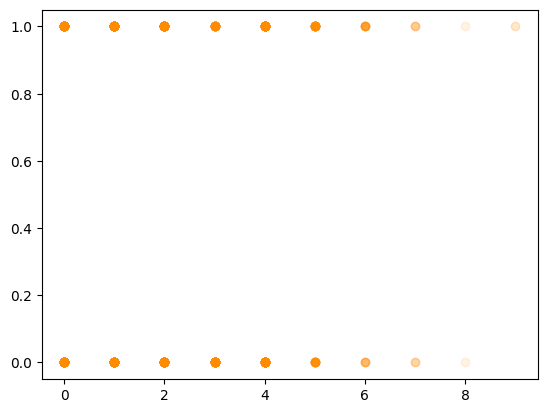

In [6]:
plt.plot(sub_df['CustServ Calls'], sub_df['target'], 'o', alpha=0.1, color='darkorange')
plt.show()

On remarque la tendance grâce à la transparence. Moins de client appellement 6, 7, 8 et 9 fois. Ce sera encore plus clair avec un histogramme.

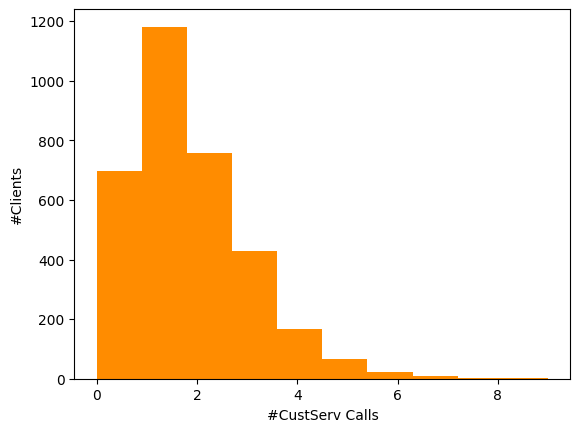

In [7]:
plt.hist(sub_df['CustServ Calls'], color='darkorange')
plt.xlabel('#CustServ Calls')
plt.ylabel('#Clients')
plt.show()

Maintenant, si on filtre en fonction de target

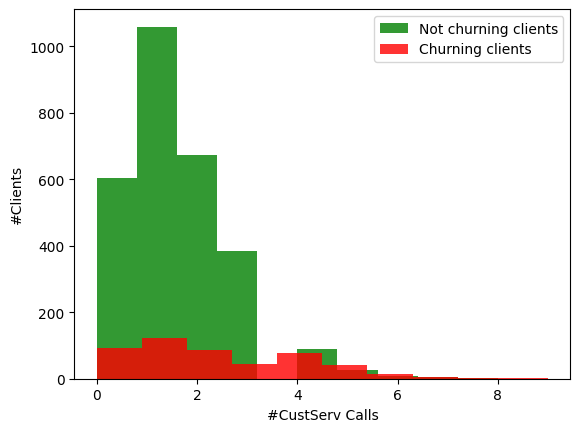

In [8]:
plt.hist(sub_df[sub_df['target']==0]['CustServ Calls'], color='green', alpha=0.8, label='Not churning clients')
plt.hist(sub_df[sub_df['target']==1]['CustServ Calls'], color='red', alpha=0.8, label='Churning clients')
plt.xlabel('#CustServ Calls')
plt.ylabel('#Clients')
plt.legend()
plt.show()

On optimise le modèle logistique

In [9]:
model = LogisticRegression()
model.fit(sub_df['CustServ Calls'].array.reshape(-1, 1), sub_df['target'])

# b0, b1
model.intercept_ , model.coef_

(array([-2.48833864]), array([[0.3954588]]))

On prédit les probabilités continues

c:\Users\Christophe\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\utils\validation.py:2742: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(


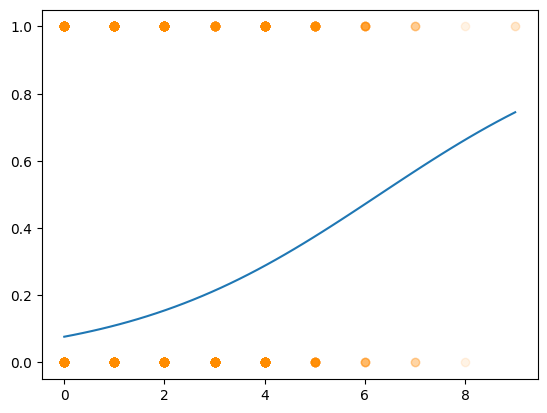

In [10]:
model_df = pd.DataFrame()

model_df['CustServ Calls'] = np.linspace(sub_df['CustServ Calls'].min(), sub_df['CustServ Calls'].max())

model_df['proba'] = model.predict_proba(model_df[['CustServ Calls']])[:,1]

plt.plot(sub_df['CustServ Calls'], sub_df['target'],'o',color='darkorange',alpha=0.1)
plt.plot(model_df['CustServ Calls'],model_df['proba'],'-')
plt.show()

# E4.2

Refaites la même chose mais cette fois en considérant successivement les montants de facture
correspondant aux appels de jours, de soirée et de nuit et finalement le montant total (une
modalité à la fois, PAS tout en même temps, j’insiste…)

Probablement qu'on aura le même genre de tendance pour d'autres dimensions...
Par exemple les coûts. 
Plus c'est cher mensuellement, plus probablement, le client aura tendance à aller voir ailleurs.
Voyons cela en nous basons sur les coûts de communication pour les appels de jour.

Commencons avec les factures de jour

In [11]:
feature = 'Day Charge'

sub_df = df[[feature,'Churn?']].copy()
sub_df['target'] = sub_df['Churn?'].apply(transform)

sub_df.head()

,Day Charge,Churn?,target
0,45.07,False.,0
1,27.47,False.,0
2,41.38,False.,0
3,50.90,False.,0
4,28.34,False.,0


In [12]:
# Variable explicative
X = sub_df.drop(columns=['Churn?', 'target'])

# Variable cible
y = sub_df['target']

# On crée le modèle
model = LogisticRegression()
model.fit(X, y)

model_df = pd.DataFrame()
model_df[feature] = np.linspace(sub_df[feature].min(), sub_df[feature].max())
model_df['proba'] = model.predict_proba(model_df[[feature]])[:,1]
model_df_day = model_df

model_df.head()

,Day Charge,proba
0,0.000000,0.019279
1,1.217143,0.020866
2,2.434286,0.022580
3,3.651429,0.024431
4,4.868571,0.026430


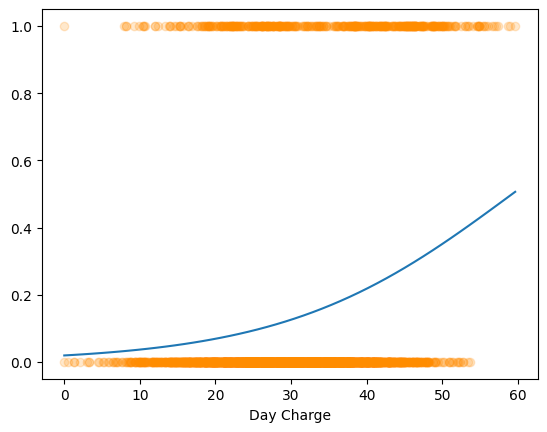

In [13]:
plt.plot(sub_df[feature], sub_df['target'],'o',color='darkorange', alpha=0.2)
plt.plot(model_df[feature],model_df['proba'],'-')
plt.xlabel(feature)
plt.show()

Maintenant pareil mais pour les charges de soirée

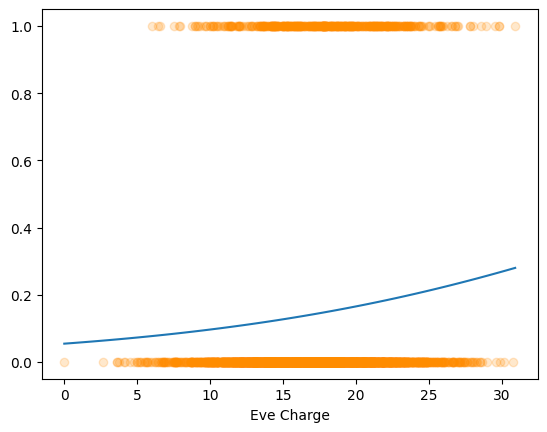

In [14]:
feature = 'Eve Charge'

sub_df = df[[feature,'Churn?']].copy()
sub_df['target'] = sub_df['Churn?'].apply(transform)

# Variable explicative
X = sub_df.drop(columns=['Churn?', 'target'])

# Variable cible
y = sub_df['target']

# On crée le modèle
model = LogisticRegression()
model.fit(X, y)

model_df = pd.DataFrame()
model_df[feature] = np.linspace(sub_df[feature].min(), sub_df[feature].max())
model_df['proba'] = model.predict_proba(model_df[[feature]])[:,1]
model_df_eve = model_df

# On affiche
plt.plot(sub_df[feature], sub_df['target'],'o',color='darkorange', alpha=0.2)
plt.plot(model_df[feature],model_df['proba'],'-')
plt.xlabel(feature)
plt.show()

Pour les appels de nuit

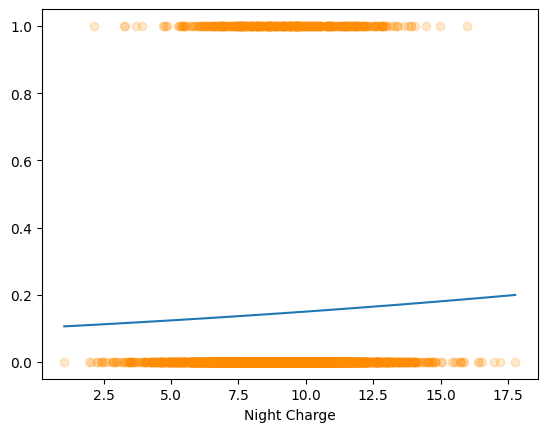

In [15]:
feature = 'Night Charge'

sub_df = df[[feature,'Churn?']].copy()
sub_df['target'] = sub_df['Churn?'].apply(transform)

# Variable explicative
X = sub_df.drop(columns=['Churn?', 'target'])

# Variable cible
y = sub_df['target']

# On crée le modèle
model = LogisticRegression()
model.fit(X, y)

model_df = pd.DataFrame()
model_df[feature] = np.linspace(sub_df[feature].min(), sub_df[feature].max())
model_df['proba'] = model.predict_proba(model_df[[feature]])[:,1]
model_df_night = model_df

# On affiche
plt.plot(sub_df[feature], sub_df['target'],'o',color='darkorange', alpha=0.2)
plt.plot(model_df[feature],model_df['proba'],'-')
plt.xlabel(feature)
plt.show()

Même conclusion.

Et maintenant, en considérant une feature dérivée, le montant total, soit la somme des trois features précédentes.

In [16]:
sub_df = df[['Day Charge','Eve Charge','Night Charge','Churn?']].copy()

sub_df['target'] = sub_df['Churn?'].apply(transform)

sub_df['Total Charge'] = sub_df.apply(lambda x:x['Day Charge']+x['Eve Charge']+x['Night Charge'], axis=1)
sub_df

,Day Charge,Eve Charge,Night Charge,Churn?,target,Total Charge
0,45.07,16.78,11.01,False.,0,72.86
1,27.47,16.62,11.45,False.,0,55.54
2,41.38,10.30,7.32,False.,0,59.00
3,50.90,5.26,8.86,False.,0,65.02
4,28.34,12.61,8.41,False.,0,49.36
...,...,...,...,...,...,...
3328,26.55,18.32,12.56,False.,0,57.43
3329,39.29,13.04,8.61,False.,0,60.94
3330,30.74,24.55,8.64,False.,0,63.93
3331,36.35,13.57,6.26,False.,0,56.18


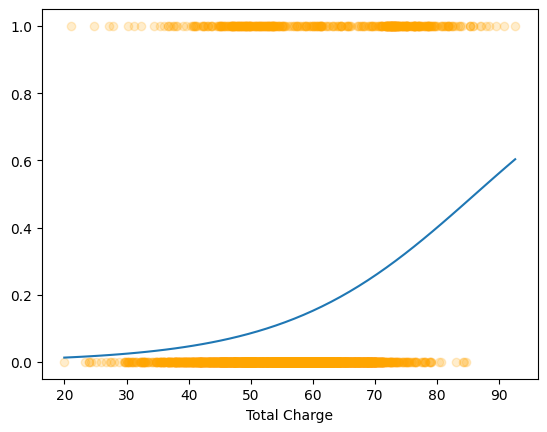

In [17]:
feature = 'Total Charge'

X = sub_df[[feature]]
y = sub_df['target']

model = LogisticRegression()
model.fit(X, y)

model_df = pd.DataFrame()

model_df[feature] = np.linspace(sub_df[feature].min(), sub_df[feature].max())
model_df['proba'] = model.predict_proba(model_df[[feature]])[:,1]
model_df_total = model_df

plt.plot(sub_df[feature], sub_df['target'],'o',color='orange',alpha=0.2)
plt.plot(model_df[feature],model_df['proba'],'-')
plt.xlabel(feature)
plt.show()

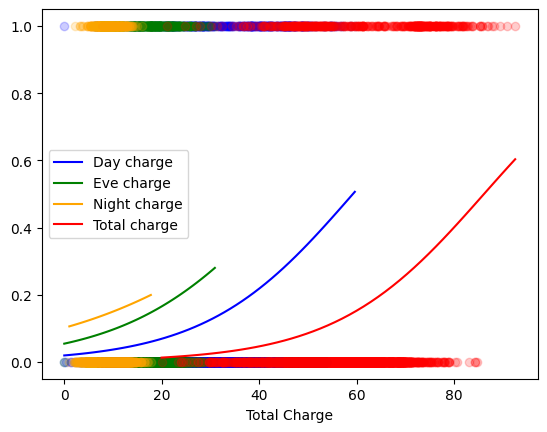

In [18]:
plt.plot(sub_df['Day Charge'], sub_df['target'],'o',alpha=0.2, color='blue')
plt.plot(sub_df['Eve Charge'], sub_df['target'],'o',alpha=0.2, color='green')
plt.plot(sub_df['Night Charge'], sub_df['target'],'o',alpha=0.2, color='orange')
plt.plot(sub_df['Total Charge'], sub_df['target'],'o',alpha=0.2, color='red')

plt.plot(model_df_day['Day Charge'],model_df_day['proba'],'-', color='blue', label='Day charge')
plt.plot(model_df_eve['Eve Charge'],model_df_eve['proba'],'-', color='green', label='Eve charge')
plt.plot(model_df_night['Night Charge'],model_df_night['proba'],'-', color='orange', label='Night charge')
plt.plot(model_df_total['Total Charge'],model_df_total['proba'],'-', color='red', label='Total charge')

plt.legend()
plt.xlabel(feature)
plt.show()

Conclusion : Le tarif de jour a le plus gros impact sur la décision de churn. La déduction classique c'est que plus le tarif devient cher, plus les clients sont succeptibles de churn.

# E4.3
- Estimez la moyenne de la facture totale sur tous les clients.
- Quelle sera la probabilité de churning pour un client payant exactement ce montant moyen ?
- Comparez à la proportion de clients partant à la concurrence calculée sur l’ensemble de la
population.
- Quelle serait votre conclusion ?
- Quelle sera la probabilité de churning pour un client payant 10% de plus ?
- Cette tendance vous semble-t-elle normale ?
- Idem pour un client payant 2 x plus

Calcul de la moyenne des factures totales :

In [24]:
## .item() pour convertir dans le type natif python
mean_charge = sub_df[[feature]].mean()[0].item()
mean_charge

C:\Users\Christophe\AppData\Local\Temp\ipykernel_20028\2491150283.py:2: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  mean_charge = sub_df[[feature]].mean()[0].item()


56.68517251725172

Calcul de la probabilité de départ pour un client qui paye un total de facture == à la moyenne :

In [ ]:
print(model.predict_proba([[mean_charge]])[:,1][0])

c:\Users\Christophe\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


array([0.126352])

Dans la population, proportion de clients partant à la concurrence :

In [ ]:
sub_df[sub_df['target']==1].shape[0]/sub_df.shape[0]

0.14491449144914492


Quelle sera la probabilité de churning pour un client payant 10% de plus ?

In [38]:
print(model.predict_proba([[1.1*mean_charge]])[:,1][0])

0.17337493749292818


c:\Users\Christophe\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


Idem pour un client payant 2 x plus

In [37]:
print(model.predict_proba([[2*mean_charge]])[:,1][0])

0.8561292044283068


c:\Users\Christophe\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(
